Exploration for Q1

In [1]:
import sys
from pathlib import Path

# find the repo root (the folder that contains src/), wherever this notebook is saved
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src" / "qkit.py").exists())
sys.path.insert(0, str(ROOT / "src"))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm
import statsmodels.formula.api as smf

import config as C
import qkit


In [2]:
df = qkit.county_year(C.Q1_YEARS).merge(
    qkit.covariates(C.Q1_YEARS).drop(columns="county_name"),
    on=["fips", "year"], how="left", validate="1:1",
)

# Wilkin has no reporting food shelf: its activity is a true zero, not unknown
no_activity = df["households"].isna() & df["fi_persons"].notna()
for m in ["households", "pounds", "individuals"]:
    df.loc[no_activity, m] = 0
    df.loc[no_activity, f"{m}_per_fi"] = 0
df.loc[no_activity, "months_observed"] = 0

print(df.shape)
df.dtypes


(261, 35)


fips                               str
county_name                        str
year                             int64
households                     float64
pounds                         float64
individuals                    float64
months_observed                float64
source_edition                     str
fi_rate                        float64
fi_persons                     float64
child_fi_rate                  float64
fi_children                    float64
cost_per_meal                  float64
annual_shortfall               float64
rucc_2013                      float64
rucc_2023                      float64
snap_threshold                 float64
pct_fi_below_snap_threshold    float64
pct_fi_above_snap_threshold    float64
households_per_fi              float64
pounds_per_fi                  float64
individuals_per_fi             float64
population                       int64
households_census                int64
poverty_rate                   float64
child_poverty_rate       

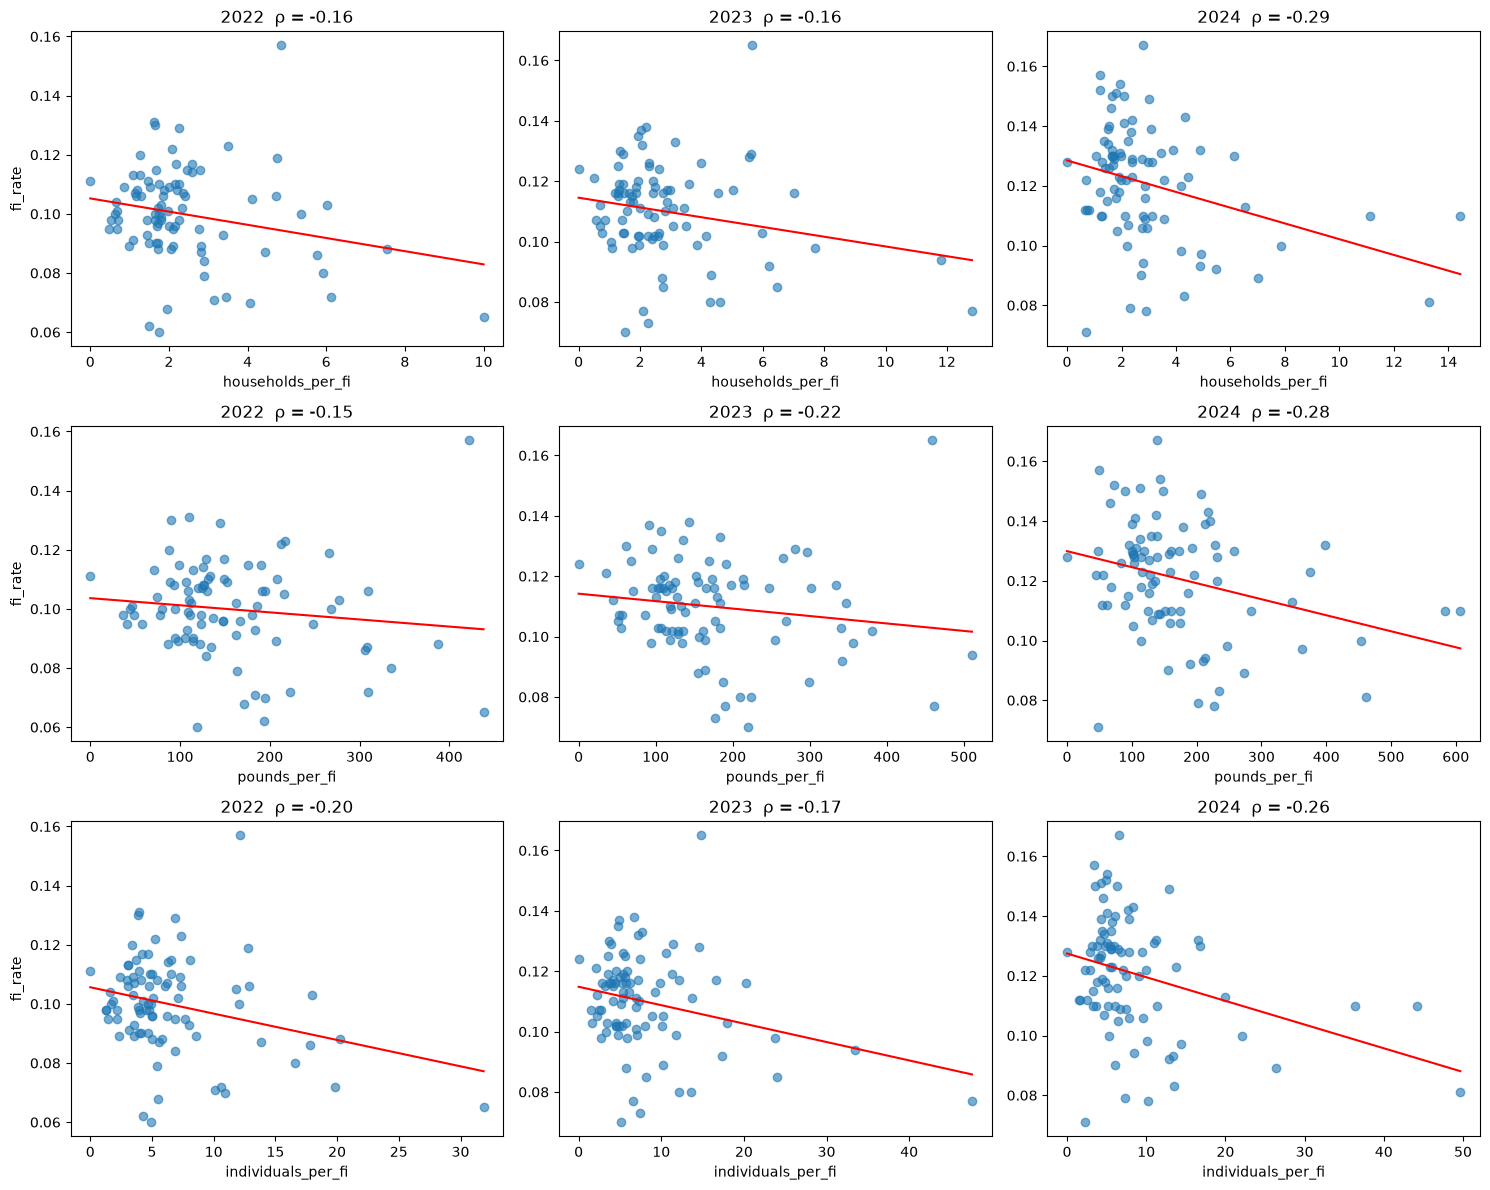

metric,households_per_fi,individuals_per_fi,pounds_per_fi
year,,,
2022,-0.164,-0.195,-0.145
2023,-0.163,-0.173,-0.219
2024,-0.293,-0.262,-0.285


In [3]:
metrics = ["households_per_fi", "pounds_per_fi", "individuals_per_fi"]
years = sorted(df["year"].unique())
fig, axes = plt.subplots(len(metrics), len(years), figsize=(5 * len(years), 4 * len(metrics)))

rows = []
for i, met in enumerate(metrics):
    for j, yr in enumerate(years):
        g = df[df["year"] == yr].dropna(subset=[met, "fi_rate"])
        ax = axes[i, j]
        ax.scatter(g[met], g["fi_rate"], alpha=0.6)
        m, b = np.polyfit(g[met], g["fi_rate"], 1)
        xs = np.linspace(g[met].min(), g[met].max(), 100)
        ax.plot(xs, m * xs + b, color="red")
        rho = g[met].corr(g["fi_rate"], method="spearman")
        ax.set_title(f"{yr}  ρ = {rho:.2f}")
        ax.set_xlabel(met)
        if j == 0:
            ax.set_ylabel("fi_rate")
        rows.append({"year": yr, "metric": met, "spearman": rho, "n": len(g)})

plt.tight_layout()
plt.show()
pd.DataFrame(rows).pivot(index="year", columns="metric", values="spearman").round(3)


### Two caveats on those correlations
1. **The negative sign is partly built in.** The x-axis divides by `fi_persons` and the
   y-axis (`fi_rate`) multiplies by it, so the two would correlate negatively even with
   random data. Activity per 1,000 *residents* does not share that term; the table below
   shows it next to the per-FI-person version. The defensible statement is *activity does
   not rise with need intensity* — not *higher need means less activity per person*.
   The residual ranking further down does not have this problem.
2. **2024 uses a different MMG edition** (2026) from 2022–23 (2025). Feeding America
   re-estimates the model each edition, so the stronger 2024 numbers may be a modelling
   change rather than a real shift. Do not describe it as a trend.

In [ ]:
count_metrics = ["households", "pounds", "individuals"]
years = sorted(df["year"].unique())
fig, axes = plt.subplots(len(count_metrics), len(years),
                         figsize=(5 * len(years), 4 * len(count_metrics)), sharey=True)

for i, met in enumerate(count_metrics):
    for j, yr in enumerate(years):
        g = df[df["year"] == yr]
        ax = axes[i, j]

        x = 1e3 * g[met] / g["population"]           # activity per 1,000 residents
        y = g["fi_rate"]
        k = g[met].sum() / g["fi_persons"].sum()      # statewide activity per food-insecure person

        ax.scatter(x, y, alpha=0.6)
        ax.margins(x=0.12)   # room for the county labels at the right edge
        m, b = np.polyfit(x, y, 1)
        xs = np.linspace(0, x.max(), 100)
        ax.plot(xs, m * xs + b, color="red", label="actual fit")
        ax.plot(xs, xs / (1e3 * k), color="grey", linestyle="--", label="if activity tracked need")

        # name the two counties a reader will ask about: the far-right dot and Wilkin at zero
        for name in [g.loc[x.idxmax(), "county_name"], "Wilkin"]:
            r = g[g["county_name"] == name].iloc[0]
            ax.annotate(name, (1e3 * r[met] / r["population"], r["fi_rate"]),
                        xytext=(4, 4), textcoords="offset points", fontsize=8)

        rho = x.corr(y, method="spearman")
        ax.set_title(f"{yr}  ρ = {rho:.2f}")
        ax.set_xlabel(f"{met} per 1,000 residents")
        if j == 0:
            ax.set_ylabel("Food insecurity rate")

axes[0, 0].legend(loc="upper left")
plt.tight_layout()
plt.show()


In [4]:
rows = []
for met in ["households", "pounds", "individuals"]:
    for yr in years:
        g = df[df["year"] == yr]
        rows.append({"year": yr, "metric": met,
                     "per food-insecure person": g[f"{met}_per_fi"].corr(g["fi_rate"], method="spearman"),
                     "per 1,000 residents": (1e3 * g[met] / g["population"]).corr(g["fi_rate"], method="spearman")})
pd.DataFrame(rows).set_index(["year", "metric"]).round(3)

,,per food-insecure person,"per 1,000 residents"
year,metric,,
2022,households,-0.164,0.093
2023,households,-0.163,0.057
2024,households,-0.293,-0.029
2022,pounds,-0.145,0.167
2023,pounds,-0.219,0.050
2024,pounds,-0.285,0.003
2022,individuals,-0.195,0.073
2023,individuals,-0.173,0.047
2024,individuals,-0.262,0.001


In [5]:
metrics = ["households", "pounds", "individuals"]
res = []
for met in metrics:
    for yr in sorted(df["year"].unique()):
        g = df[(df["year"] == yr) & (df[met] > 0)].dropna(subset=["fi_persons"]).copy()
        fit = smf.ols(f"np.log({met}) ~ np.log(fi_persons)", data=g).fit()
        g["resid"] = fit.resid
        res.append(g[["fips", "county_name", "year", "months_observed", "fi_rate", "resid"]]
                   .assign(metric=met))
res = pd.concat(res)

# counties below the line in every metric and year = consistently underserved
summary = (res.groupby(["county_name"])
              .agg(mean_resid=("resid", "mean"),
                   n_below=("resid", lambda r: (r < 0).sum()),
                   n=("resid", "size"),
                   min_months=("months_observed", "min"))
              .sort_values("mean_resid"))
print("Estimated need > observed demand")
display(summary.head(10).round(3))
print("Observed demand > estimated need")
display(summary.tail(10).round(3))


Estimated need > observed demand


,mean_resid,n_below,n,min_months
county_name,,,,
Nicollet,-1.208,9,9,12.0
Pope,-0.942,9,9,12.0
Lac qui Parle,-0.882,9,9,12.0
Benton,-0.877,9,9,12.0
Norman,-0.867,9,9,12.0
Roseau,-0.760,9,9,12.0
Scott,-0.673,7,9,12.0
Nobles,-0.635,8,9,12.0
Todd,-0.552,9,9,12.0


Observed demand > estimated need


,mean_resid,n_below,n,min_months
county_name,,,,
Dodge,0.680,0,9,12.0
Olmsted,0.733,0,9,12.0
Pipestone,0.757,0,9,12.0
Kittson,0.780,0,9,12.0
Mahnomen,0.865,0,9,12.0
Cook,0.890,0,9,12.0
Renville,1.034,0,9,12.0
Rice,1.069,0,9,12.0
Washington,1.211,0,9,12.0


### Robustness: food-shelf-like sites only
The frame above counts every site type. Some counties get a large share of their pounds
from sites that are not food shelves (Cook 57%, Faribault 50%, Anoka 47%). Re-run the
ranking with only food-shelf-like sites and see which counties move.

In [6]:
df_fs = qkit.county_year(C.Q1_YEARS, food_shelf_only=True)
res_fs = []
for met in ["households", "pounds", "individuals"]:
    for yr in years:
        g = df_fs[(df_fs["year"] == yr) & (df_fs[met] > 0)].copy()
        g["resid"] = smf.ols(f"np.log({met}) ~ np.log(fi_persons)", data=g).fit().resid
        res_fs.append(g[["county_name", "resid"]])

cmp = pd.DataFrame({"all_sites": summary["mean_resid"],
                    "food_shelf_only": pd.concat(res_fs).groupby("county_name")["resid"].mean()})
cmp["shift"] = cmp["food_shelf_only"] - cmp["all_sites"]
print("Spearman between the two rankings:",
      round(cmp["all_sites"].corr(cmp["food_shelf_only"], method="spearman"), 3))
cmp.reindex(cmp["shift"].abs().sort_values(ascending=False).index).head(5).round(2)

Spearman between the two rankings: 0.936


,all_sites,food_shelf_only,shift
county_name,,,
Cook,0.89,-0.12,-1.01
Faribault,0.04,-0.82,-0.86
Anoka,0.59,0.11,-0.48
Carlton,-0.42,-0.88,-0.46
Mower,0.06,-0.32,-0.38


## Where estimated need and observed demand disagree
Mean residual across all 9 metric-years.

- **Red:** estimated need is higher than observed demand. Fewer people show up at food
  shelves than the county's food-insecure population predicts.
- **Blue:** observed demand is higher than estimated need. More people show up than the
  county's own population predicts.

Several red counties border blue ones (Nicollet / Blue Earth, Roseau / Kittson,
Benton / Sherburne), which is consistent with residents crossing county lines to the
nearest food shelf rather than going unserved. Counties marked * had fewer than 12 months
of reporting in some year, so part of their gap may be missing data.

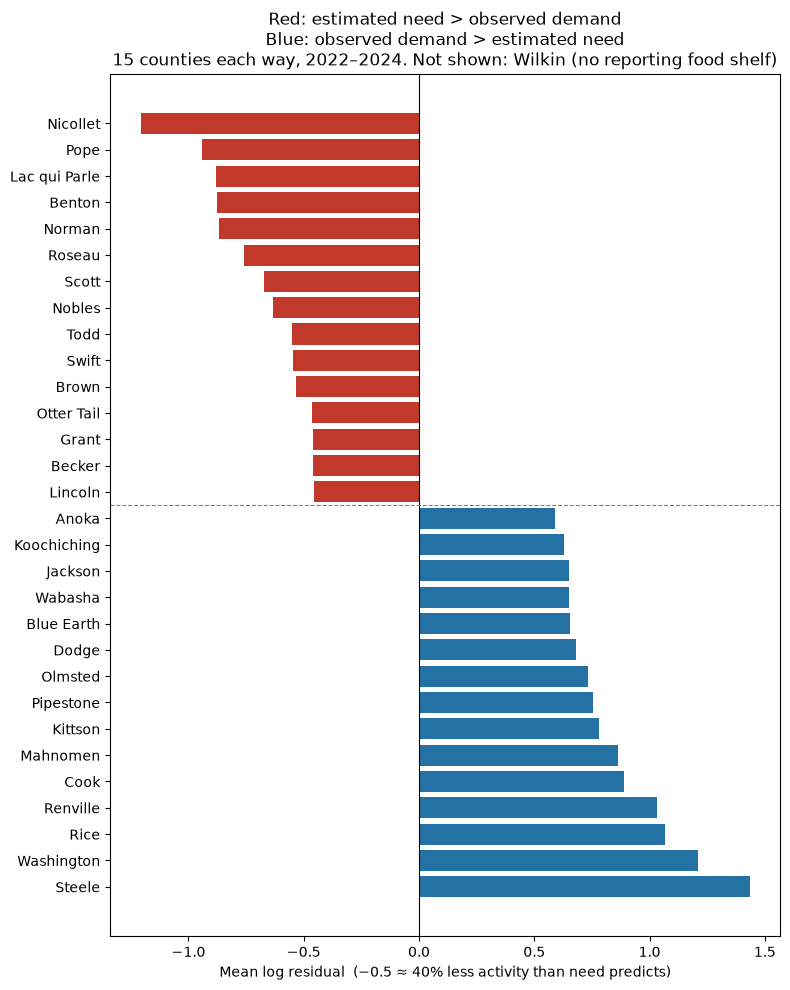

In [ ]:
k = 15
show = pd.concat([summary.head(k), summary.tail(k)])
labels = [f"{c} *" if mm < 12 else c for c, mm in zip(show.index, show["min_months"])]
colors = ["#c0392b" if v < 0 else "#2471a3" for v in show["mean_resid"]]

fig, ax = plt.subplots(figsize=(8, 10))
ax.barh(range(len(show)), show["mean_resid"], color=colors)
ax.set_yticks(range(len(show)), labels)
ax.invert_yaxis()
ax.axvline(0, color="black", lw=0.8)
ax.axhline(k - 0.5, color="grey", ls="--", lw=0.8)
ax.set_xlabel("Mean log residual  (−0.5 ≈ 40% less activity than need predicts)")
ax.set_title("Red: estimated need > observed demand\n"
             "Blue: observed demand > estimated need\n"
             f"{k} counties each way, 2022–2024. Not shown: Wilkin (no reporting food shelf)")
plt.tight_layout()
plt.show()